# 使用Scikit-Learn 完成預測
### Scikit-Learn在三個面向提供支援。
1. 獲取資料:***klearn.datasets***
2. 掌握資料:***sklearn.preprocessing*** 
3. 機器學習:***sklearn Estimator API*** 

獲取資料的方式有很多種（包含檔案、資料庫、網路爬蟲、Kaggle Datasets等），<br>
其中最簡單的方式是從Sklearn import 內建的資料庫。由於其特性隨手可得且不用下載，所以我們通常叫他**玩具資料**：

# 基本架構

* 讀取資料&pre-processing
* 切分訓練集與測試集 
* 模型配適
* 預測 
* 評估(計算成績可能是誤差值或正確率或..)


In [2]:
%matplotlib inline

from sklearn import datasets
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 讀取Iris資料集與資料前處理

Iris Flowers 資料集

我們在這個項目中使用 Iris Data Set，這個資料集中的每個樣本有4個特徵，1個類別。該資料集1中的樣本類別數為3類，每類樣本數目為50個，總共150個樣本。

屬性資訊：

    花萼長度 sepal length(cm)
    花萼寬度 sepal width(cm)
    花瓣長度 petal length(cm)
    花瓣寬度 petal width(cm)
    類別：
        Iris Setosa
        Iris Versicolour
        Iris Virginica

樣本特徵資料是數值型的，而且單位都相同（釐米）。

![Iris Flowers](images/iris_data.PNG)


In [5]:
iris = datasets.load_iris()
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

* 印出iris的key值與檔案位置
* 查看前10筆資料
* 查看資料型別
* 印出標註的樣本類別資料

In [6]:
print(f"Iris 的 keys：{list(iris.keys())}")
print(f"資料檔位置：{iris.get('filename', 'sklearn 內建資料')}")
print(f"資料型別：{type(iris.data)}")
print(f"前 10 筆：\n{iris.data[:10]}")
print(f"類別標籤：{iris.target_names}")
print(f"前 10 筆標籤：{iris.target[:10]}")

Iris 的 keys：['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module']
資料檔位置：iris.csv
資料型別：<class 'numpy.ndarray'>
前 10 筆：
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]]
類別標籤：['setosa' 'versicolor' 'virginica']
前 10 筆標籤：[0 0 0 0 0 0 0 0 0 0]


In [7]:
# 先用前兩個特徵來練習分類
data = iris.data[:, :2]
print(f"資料形狀：{data.shape}")

資料形狀：(150, 2)


In [8]:
#以下是組成 pandas DataFrame (也可以不用這種做)
x = pd.DataFrame(data, columns=iris['feature_names'][:2])
x.head(10)

,sepal length (cm),sepal width (cm)
0,5.1,3.5
1,4.9,3.0
2,4.7,3.2
3,4.6,3.1
4,5.0,3.6
5,5.4,3.9
6,4.6,3.4
7,5.0,3.4
8,4.4,2.9
9,4.9,3.1


In [9]:
x.describe()

,sepal length (cm),sepal width (cm)
count,150.000000,150.000000
mean,5.843333,3.057333
std,0.828066,0.435866
min,4.300000,2.000000
25%,5.100000,2.800000
50%,5.800000,3.000000
75%,6.400000,3.300000
max,7.900000,4.400000


In [10]:
#建立Target欄位與資料
y = pd.DataFrame(iris.target, columns=['target'])
y.head()

,target
0,0
1,0
2,0
3,0
4,0


In [11]:
#合併資料特徵欄位與目標欄位
df = pd.concat([x, y], axis=1)
df.head()

,sepal length (cm),sepal width (cm),target
0,5.1,3.5,0
1,4.9,3.0,0
2,4.7,3.2,0
3,4.6,3.1,0
4,5.0,3.6,0


In [12]:
#只選擇目標為0與1的資料
df = df[df['target'].isin([0, 1])]
X = df.drop(columns=['target'])
y = df['target']
print(f"留下 {len(df)} 筆資料")

留下 100 筆資料


## 切分訓練集與測試集
> train_test_split()

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"訓練資料：{len(X_train)} 筆，測試資料：{len(X_test)} 筆")

訓練資料：80 筆，測試資料：20 筆


In [14]:
X_train.head()

,sepal length (cm),sepal width (cm)
15,5.7,4.4
52,6.9,3.1
60,5.0,2.0
66,5.6,3.0
68,6.2,2.2


In [15]:
X_test.head()

,sepal length (cm),sepal width (cm)
57,4.9,2.4
77,6.7,3.0
63,6.1,2.9
51,6.4,3.2
7,5.0,3.4


### 模型配適、預測與評估
先用簡單的 Logistic Regression 練習基本流程。

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f"測試集準確率：{accuracy_score(y_test, y_pred):.2f}")

測試集準確率：1.00


# Appendix 

>normalization和standardization是差不多的<br>
都是把數據進行前處理，從而使數值都落入到統一的數值範圍，從而在建模過程中，各個特徵量沒差別對待。<br> 
* normalization一般是把數據限定在需要的範圍，比如一般都是【0，1】，從而消除了數據量綱對建模的影響。<br> 
* standardization 一般是指將數據正態化，使平均值0方差為1.<br> 

因此normalization和standardization 是針對數據而言的，消除一些數值差異帶來的特種重要性偏見。<br>
經過歸一化的數據，能加快訓練速度，促進算法的收斂。

### Standardization (z-score)
    to compute the mean and standard deviation on a training set so as to be able to later reapply the same transformation on the testing set. 

In [17]:
def norm_stats(dfs):
    minimum = dfs.min()
    maximum = dfs.max()
    mu = dfs.mean()
    sigma = dfs.std(ddof=0)
    return (minimum, maximum, mu, sigma)


def z_score(col, stats):
    m, M, mu, s = stats
    df = pd.DataFrame(index=col.index)
    for c in col.columns:
        df[c] = (col[c] - mu[c]) / s[c]
    return df

In [18]:
stats = norm_stats(X_train)
arr_x_train = np.array(z_score(X_train, stats))
arr_y_train = np.array(y_train)
arr_x_train[:5]

array([[ 0.39315746,  2.71956762],
       [ 2.33867889,  0.03612329],
       [-0.74173005, -2.23448345],
       [ 0.23103067, -0.17029551],
       [ 1.20379139, -1.82164586]])

## use sklearn

In [19]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(X_train)  #Compute the statistics to be used for later scaling.
print(sc.mean_)  #mean
print(sc.scale_) #standard deviation

[5.4575 3.0825]
[0.61680122 0.48445201]


In [17]:
#transform: (x-u)/std.
X_train_std = sc.transform(X_train)
X_train_std[:5]

array([[ 0.39315746,  2.71956762],
       [ 2.33867889,  0.03612329],
       [-0.74173005, -2.23448345],
       [ 0.23103067, -0.17029551],
       [ 1.20379139, -1.82164586]])

The scaler instance can then be used on new data to transform it the same way it did on the training set:

In [18]:
X_test_std = sc.transform(X_test)
print(X_test_std[:10])

[[-0.90385683 -1.40880827]
 [ 2.01442531 -0.17029551]
 [ 1.0416646  -0.3767143 ]
 [ 1.52804496  0.24254208]
 [-0.74173005  0.65537967]
 [ 0.55528424  1.89389244]
 [-0.0932229   0.65537967]
 [ 1.85229853 -0.17029551]
 [ 0.39315746  1.48105485]
 [-1.39023719  1.06821726]]


you can also use fit_transform method (i.e., fit and then transform)    

In [19]:
# fit_transform 只對訓練集使用，測試集使用同一套參數
X_train_std = sc.fit_transform(X_train)
X_test_std = sc.transform(X_test)
print(f"測試集前 10 筆：\n{X_test_std[:10]}")

測試集前 10 筆：
[[-0.90385683 -1.40880827]
 [ 2.01442531 -0.17029551]
 [ 1.0416646  -0.3767143 ]
 [ 1.52804496  0.24254208]
 [-0.74173005  0.65537967]
 [ 0.55528424  1.89389244]
 [-0.0932229   0.65537967]
 [ 1.85229853 -0.17029551]
 [ 0.39315746  1.48105485]
 [-1.39023719  1.06821726]]


In [20]:
print(f"訓練集平均：{np.round(X_train_std.mean(axis=0), 4)}")
print(f"訓練集標準差：{np.round(X_train_std.std(axis=0), 4)}")

訓練集平均：[-0.  0.]
訓練集標準差：[1. 1.]


## Min-Max Normaliaztion
    Transforms features by scaling each feature to a given range.
    The transformation is given by:

    X' = X - X.min(axis=0) / ((X.max(axis=0) - X.min(axis=0))
    X -> N 維資料
    


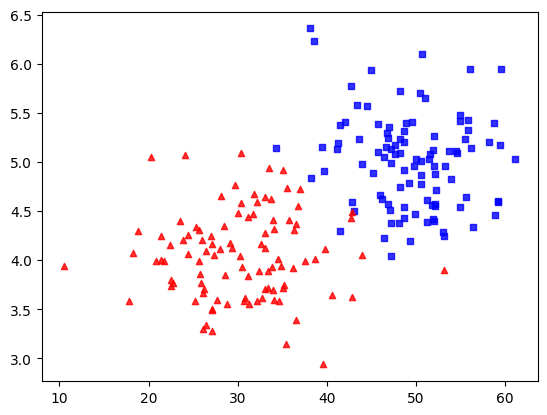

第一組 x 平均：49.38
第二組 x 平均：30.39


In [21]:
np.random.seed(42)
x1 = np.random.normal(50, 6, 100)
y1 = np.random.normal(5, 0.5, 100)
x2 = np.random.normal(30, 6, 100)
y2 = np.random.normal(4, 0.5, 100)

plt.scatter(x1, y1, c='b', marker='s', s=20, alpha=0.8)
plt.scatter(x2, y2, c='r', marker='^', s=20, alpha=0.8)
plt.show()
print(f"第一組 x 平均：{np.mean(x1):.2f}")
print(f"第二組 x 平均：{np.mean(x2):.2f}")

In [22]:
x_val = np.concatenate((x1,x2))
y_val = np.concatenate((y1,y2))

x_val.shape

(200,)

In [23]:
def minmax_norm(X):
    return (X - X.min(axis=0)) / ((X.max(axis=0) - X.min(axis=0)))

In [24]:
minmax_norm(x_val[:10])

array([0.4716135 , 0.16166943, 0.54530673, 0.97257612, 0.1148643 ,
       0.11487231, 1.        , 0.60375694, 0.        , 0.49399168])

In [25]:
from sklearn.preprocessing import MinMaxScaler
x_val=x_val.reshape(-1, 1)
scaler = MinMaxScaler().fit(x_val)  # default range 0~1
print(scaler.data_max_)
print(scaler.transform(x_val)[:10])

[61.11366911]
[[0.83913807]
 [0.76378651]
 [0.85705388]
 [0.96092879]
 [0.75240755]
 [0.7524095 ]
 [0.96759591]
 [0.87126391]
 [0.7244825 ]
 [0.8445785 ]]


In [26]:
# 比較自己寫的正規化與 sklearn 的結果
x_scaled = scaler.transform(x_val)
print(f"正規化最小值：{x_scaled.min():.2f}")
print(f"正規化最大值：{x_scaled.max():.2f}")

正規化最小值：0.00
正規化最大值：1.00
